<a href="https://colab.research.google.com/github/Yuuraajaa/Tito_Dwi_Saputro_2411007-Sistem_Cerdas/blob/main/Salinan_dari_praktikum_p3_fis_mamdani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 3 — Fuzzy Inference System (FIS) Mamdani
**Mata Kuliah:** Sistem Cerdas (INF2303029) · **Sub-CPMK:** merancang FIS Mamdani untuk kasus pengambilan keputusan · **Penilaian:** Tugas Praktikum 1

**Nama / NIM:** Tito Dwi Saputro/2411007

**Kasus:** pengendali kecepatan kipas dengan input *Suhu* (0-50 °C) dan *Kelembapan* (0-100 %), output *Kecepatan Kipas* (0-100 %).

Alur: (A) mendefinisikan himpunan fuzzy, (B) fuzzifikasi, (C) Mamdani langkah demi langkah, (D) FIS dengan `scikit-fuzzy`, (E) analisis, (F) tugas mandiri.

In [ ]:
!pip install -q scikit-fuzzy

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

## A. Himpunan fuzzy
Semesta dibuat dengan `np.arange`; fungsi keanggotaan memakai `trimf` (segitiga) dan `trapmf` (trapesium). Parameter sama dengan materi Pertemuan 2-3.

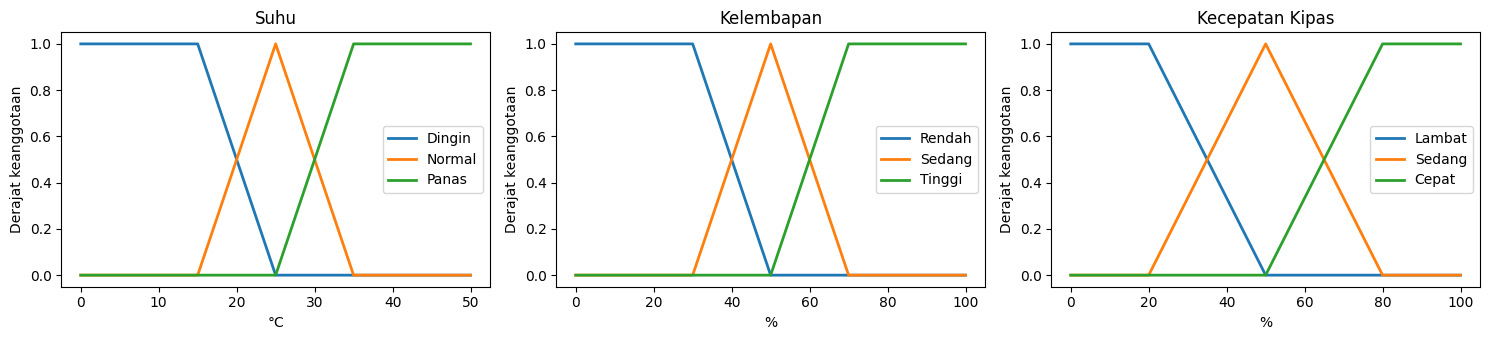

In [ ]:
x_suhu = np.arange(0, 50.1, 0.5)
x_lembap = np.arange(0, 100.1, 1)
x_kipas = np.arange(0, 100.1, 1)

suhu = {
    'Dingin': fuzz.trapmf(x_suhu, [0, 0, 15, 25]),
    'Normal': fuzz.trimf(x_suhu, [15, 25, 35]),
    'Panas':  fuzz.trapmf(x_suhu, [25, 35, 50, 50]),
}
lembap = {
    'Rendah': fuzz.trapmf(x_lembap, [0, 0, 30, 50]),
    'Sedang': fuzz.trimf(x_lembap, [30, 50, 70]),
    'Tinggi': fuzz.trapmf(x_lembap, [50, 70, 100, 100]),
}
kipas = {
    'Lambat': fuzz.trapmf(x_kipas, [0, 0, 20, 50]),
    'Sedang': fuzz.trimf(x_kipas, [20, 50, 80]),
    'Cepat':  fuzz.trapmf(x_kipas, [50, 80, 100, 100]),
}

def plot_sets(ax, x, sets, title, xlabel):
    for nama, mu in sets.items():
        ax.plot(x, mu, label=nama, linewidth=2)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('Derajat keanggotaan')
    ax.set_ylim(-0.05, 1.05); ax.legend()

fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
plot_sets(axs[0], x_suhu, suhu, 'Suhu', '°C')
plot_sets(axs[1], x_lembap, lembap, 'Kelembapan', '%')
plot_sets(axs[2], x_kipas, kipas, 'Kecepatan Kipas', '%')
plt.tight_layout(); plt.show()

## B. Fuzzifikasi
`interp_membership` menghitung derajat keanggotaan sebuah nilai crisp. Bandingkan dengan hitungan manual di materi (Suhu 28 → Normal 0,7, Panas 0,3).

In [ ]:
T, H = 28, 60
mu_suhu   = {k: fuzz.interp_membership(x_suhu, v, T) for k, v in suhu.items()}
mu_lembap = {k: fuzz.interp_membership(x_lembap, v, H) for k, v in lembap.items()}
print('Suhu', T, '->', {k: round(float(v), 2) for k, v in mu_suhu.items()})
print('Kelembapan', H, '->', {k: round(float(v), 2) for k, v in mu_lembap.items()})

Suhu 28 -> {'Dingin': 0.0, 'Normal': 0.7, 'Panas': 0.3}
Kelembapan 60 -> {'Rendah': 0.0, 'Sedang': 0.5, 'Tinggi': 0.5}


## C. Mamdani langkah demi langkah (tanpa library kontrol)
1. Evaluasi aturan: AND = `min`.
2. Implikasi: potong himpunan output (`np.fmin`).
3. Agregasi: gabungkan dengan `max`.
4. Defuzzifikasi: centroid.

Tabel rule base: baris = Suhu, kolom = Kelembapan.

IF Suhu=Normal AND Kelembapan=Sedang THEN Kipas=Sedang | kekuatan=0.50
IF Suhu=Normal AND Kelembapan=Tinggi THEN Kipas=Cepat | kekuatan=0.50
IF Suhu=Panas AND Kelembapan=Sedang THEN Kipas=Cepat | kekuatan=0.30
IF Suhu=Panas AND Kelembapan=Tinggi THEN Kipas=Cepat | kekuatan=0.30

Output centroid (manual) = 63.62 %   (perkiraan hitungan tangan: 63,6 %)


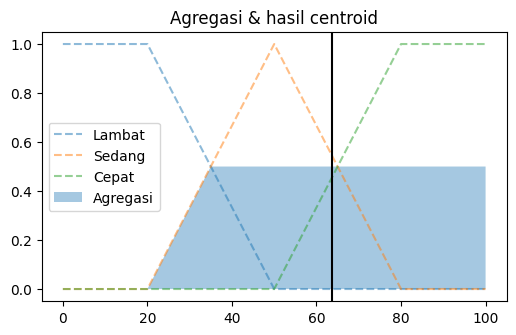

In [ ]:
rules = {
    ('Dingin','Rendah'):'Lambat', ('Dingin','Sedang'):'Lambat', ('Dingin','Tinggi'):'Sedang',
    ('Normal','Rendah'):'Lambat', ('Normal','Sedang'):'Sedang', ('Normal','Tinggi'):'Cepat',
    ('Panas','Rendah'):'Sedang',  ('Panas','Sedang'):'Cepat',   ('Panas','Tinggi'):'Cepat',
}

def mamdani(T, H, metode='centroid', tampil=False):
    ms = {k: fuzz.interp_membership(x_suhu, v, T) for k, v in suhu.items()}
    ml = {k: fuzz.interp_membership(x_lembap, v, H) for k, v in lembap.items()}
    agregat = np.zeros_like(x_kipas, dtype=float)
    for (s, l), out in rules.items():
        kekuatan = min(ms[s], ml[l])                       # AND = min
        if kekuatan > 0 and tampil:
            print(f'IF Suhu={s} AND Kelembapan={l} THEN Kipas={out} | kekuatan={kekuatan:.2f}')
        terpotong = np.fmin(kekuatan, kipas[out])         # implikasi (clipping)
        agregat = np.fmax(agregat, terpotong)             # agregasi (max)
    return fuzz.defuzz(x_kipas, agregat, metode), agregat

hasil, agregat = mamdani(28, 60, tampil=True)
print(f'\nOutput centroid (manual) = {hasil:.2f} %   (perkiraan hitungan tangan: 63,6 %)')

plt.figure(figsize=(6, 3.5))
for nama, mu in kipas.items():
    plt.plot(x_kipas, mu, '--', alpha=.5, label=nama)
plt.fill_between(x_kipas, agregat, alpha=.4, label='Agregasi')
plt.axvline(hasil, color='k'); plt.title('Agregasi & hasil centroid'); plt.legend(); plt.show()

## D. FIS dengan `scikit-fuzzy` (`skfuzzy.control`)
Library membungkus langkah di atas. Hasilnya harus sangat dekat dengan bagian C.

Output skfuzzy = 63.62 %


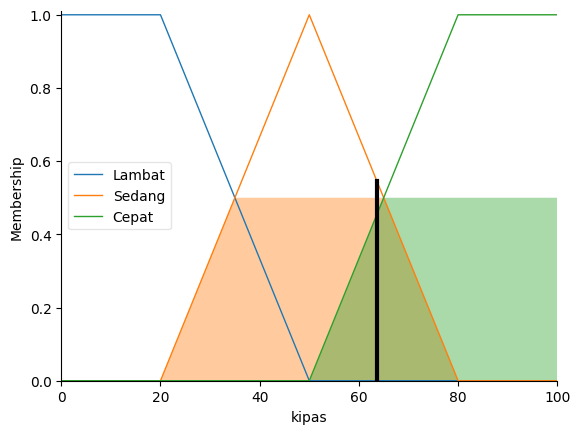

In [ ]:
suhu_v   = ctrl.Antecedent(x_suhu, 'suhu')
lembap_v = ctrl.Antecedent(x_lembap, 'lembap')
kipas_v  = ctrl.Consequent(x_kipas, 'kipas')   # defuzzifikasi default: centroid

for k, v in suhu.items():   suhu_v[k] = v
for k, v in lembap.items(): lembap_v[k] = v
for k, v in kipas.items():  kipas_v[k] = v

aturan = [ctrl.Rule(suhu_v[s] & lembap_v[l], kipas_v[o]) for (s, l), o in rules.items()]
sistem = ctrl.ControlSystem(aturan)

def kontrol(T, H):
    sim = ctrl.ControlSystemSimulation(sistem)
    sim.input['suhu'] = T
    sim.input['lembap'] = H
    sim.compute()
    return sim

sim = kontrol(28, 60)
print('Output skfuzzy =', round(sim.output['kipas'], 2), '%')
kipas_v.view(sim=sim)

## E. Analisis

Suhu | Lembap | Kipas (%)
  10 |     20 | 18.6
  20 |     80 | 63.6
  28 |     60 | 63.6
  35 |     40 | 63.6
  45 |     90 | 81.4


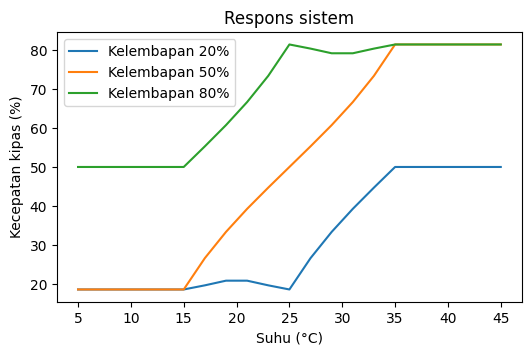

In [ ]:
print('Suhu | Lembap | Kipas (%)')
for T, H in [(10, 20), (20, 80), (28, 60), (35, 40), (45, 90)]:
    print(f'{T:4} | {H:6} | {kontrol(T, H).output["kipas"]:.1f}')

plt.figure(figsize=(6, 3.5))
sx = np.arange(5, 46, 2)
for H in (20, 50, 80):
    plt.plot(sx, [kontrol(t, H).output['kipas'] for t in sx], label=f'Kelembapan {H}%')
plt.xlabel('Suhu (°C)'); plt.ylabel('Kecepatan kipas (%)'); plt.legend(); plt.title('Respons sistem'); plt.show()

In [ ]:
# Perbandingan metode defuzzifikasi pada kasus yang sama
for m in ['centroid', 'bisector', 'mom', 'som', 'lom']:
    h, _ = mamdani(28, 60, metode=m)
    print(f'{m:9}: {h:.2f}')

centroid : 63.62
bisector : 63.75
mom      : 67.50
som      : 35.00
lom      : 100.00


## F. Tugas mandiri
Kerjakan di sel di bawah dan jawab pertanyaan pada sel markdown terakhir.

1. **Hitung manual** (kertas/foto) output untuk Suhu = 20, Kelembapan = 80, lalu bandingkan dengan `kontrol(20, 80)`.
2. **Modifikasi:** ubah satu aturan atau parameter satu himpunan. Bagaimana kurva respons berubah?
3. **Rancang FIS sendiri** (kasus bebas, misal AC, lampu otomatis, penyiraman tanaman): minimal 2 input, 1 output, 3 himpunan tiap variabel, minimal 6 aturan. Sertakan plot himpunan, tabel rule base, dan minimal 3 skenario uji.

In [ ]:

!pip -q install scikit-fuzzy

import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

suhu = ctrl.Antecedent(np.arange(0, 41, 1), 'suhu')
kelembapan = ctrl.Antecedent(np.arange(0, 101, 1), 'kelembapan')
kipas = ctrl.Consequent(np.arange(0, 101, 1), 'kipas')

suhu['dingin'] = fuzz.trapmf(suhu.universe, [0, 0, 15, 22])
suhu['normal'] = fuzz.trimf(suhu.universe, [18, 25, 32])
suhu['panas'] = fuzz.trapmf(suhu.universe, [28, 35, 40, 40])

kelembapan['rendah'] = fuzz.trapmf(
    kelembapan.universe, [0, 0, 30, 50]
)
kelembapan['sedang'] = fuzz.trimf(
    kelembapan.universe, [30, 50, 70]
)
kelembapan['tinggi'] = fuzz.trapmf(
    kelembapan.universe, [50, 70, 100, 100]
)

kipas['lambat'] = fuzz.trapmf(kipas.universe, [0, 0, 20, 40])
kipas['sedang'] = fuzz.trimf(kipas.universe, [25, 50, 75])
kipas['cepat'] = fuzz.trapmf(kipas.universe, [60, 80, 100, 100])

aturan = [
    ctrl.Rule(suhu['dingin'] & kelembapan['rendah'], kipas['lambat']),
    ctrl.Rule(suhu['dingin'] & kelembapan['sedang'], kipas['lambat']),
    ctrl.Rule(suhu['dingin'] & kelembapan['tinggi'], kipas['sedang']),

    ctrl.Rule(suhu['normal'] & kelembapan['rendah'], kipas['lambat']),
    ctrl.Rule(suhu['normal'] & kelembapan['sedang'], kipas['sedang']),
    ctrl.Rule(suhu['normal'] & kelembapan['tinggi'], kipas['cepat']),

    ctrl.Rule(suhu['panas'] & kelembapan['rendah'], kipas['sedang']),
    ctrl.Rule(suhu['panas'] & kelembapan['sedang'], kipas['cepat']),
    ctrl.Rule(suhu['panas'] & kelembapan['tinggi'], kipas['cepat'])
]

sistem = ctrl.ControlSystem(aturan)

def kontrol(nilai_suhu, nilai_kelembapan):
    simulasi = ctrl.ControlSystemSimulation(sistem)
    simulasi.input['suhu'] = nilai_suhu
    simulasi.input['kelembapan'] = nilai_kelembapan
    simulasi.compute()
    return simulasi

print("Sistem Fuzzy Mamdani berhasil dibuat!")


Sistem Fuzzy Mamdani berhasil dibuat!


In [ ]:
# TODO 1: bandingkan hitungan manual Anda dengan keluaran sistem
print(kontrol(20, 80).output['kipas'])

64.25595238095237


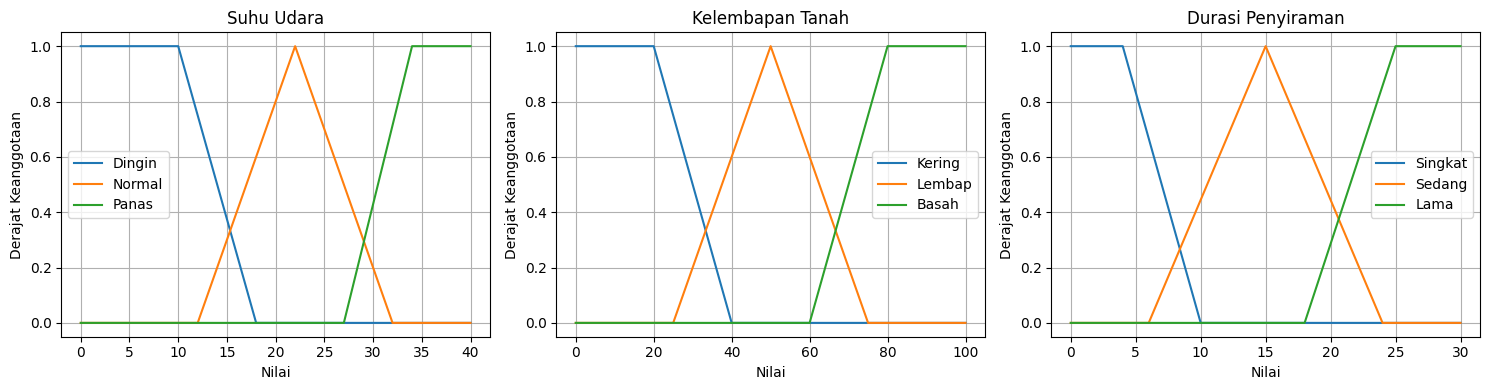

,Suhu,Kelembapan Tanah,Output
0,Dingin,Kering,Sedang
1,Dingin,Lembap,Singkat
2,Dingin,Basah,Singkat
3,Normal,Kering,Lama
4,Normal,Lembap,Singkat
5,Normal,Basah,Singkat
6,Panas,Kering,Lama
7,Panas,Lembap,Sedang
8,Panas,Basah,Singkat


,Suhu (°C),Kelembapan Tanah (%),Durasi Penyiraman (menit)
0,15,20,18.24
1,25,50,4.04
2,35,30,21.03


In [ ]:
# TODO 3: FIS rancangan sendiri

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# 1. Membuat variabel fuzzy
suhu = ctrl.Antecedent(np.arange(0, 41, 1), 'suhu')
tanah = ctrl.Antecedent(np.arange(0, 101, 1), 'tanah')
durasi = ctrl.Consequent(np.arange(0, 31, 1), 'durasi')

# 2. Membuat membership function
suhu['dingin'] = fuzz.trapmf(suhu.universe, [0, 0, 10, 18])
suhu['normal'] = fuzz.trimf(suhu.universe, [12, 22, 32])
suhu['panas'] = fuzz.trapmf(suhu.universe, [27, 34, 40, 40])

tanah['kering'] = fuzz.trapmf(tanah.universe, [0, 0, 20, 40])
tanah['lembap'] = fuzz.trimf(tanah.universe, [25, 50, 75])
tanah['basah'] = fuzz.trapmf(tanah.universe, [60, 80, 100, 100])

durasi['singkat'] = fuzz.trapmf(durasi.universe, [0, 0, 4, 10])
durasi['sedang'] = fuzz.trimf(durasi.universe, [6, 15, 24])
durasi['lama'] = fuzz.trapmf(durasi.universe, [18, 25, 30, 30])

# 3. Membuat rule base
aturan = [
    ctrl.Rule(suhu['dingin'] & tanah['kering'], durasi['sedang']),
    ctrl.Rule(suhu['dingin'] & tanah['lembap'], durasi['singkat']),
    ctrl.Rule(suhu['dingin'] & tanah['basah'], durasi['singkat']),
    ctrl.Rule(suhu['normal'] & tanah['kering'], durasi['lama']),
    ctrl.Rule(suhu['normal'] & tanah['lembap'], durasi['singkat']),
    ctrl.Rule(suhu['normal'] & tanah['basah'], durasi['singkat']),
    ctrl.Rule(suhu['panas'] & tanah['kering'], durasi['lama']),
    ctrl.Rule(suhu['panas'] & tanah['lembap'], durasi['sedang']),
    ctrl.Rule(suhu['panas'] & tanah['basah'], durasi['singkat'])
]

# 4. Membuat sistem Fuzzy Mamdani
sistem_tanaman = ctrl.ControlSystem(aturan)

def kontrol_tanaman(nilai_suhu, kelembapan_tanah):
    simulasi = ctrl.ControlSystemSimulation(sistem_tanaman)
    simulasi.input['suhu'] = nilai_suhu
    simulasi.input['tanah'] = kelembapan_tanah
    simulasi.compute()
    return simulasi.output['durasi']

# 5. Plot himpunan fuzzy
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for variabel, ax, judul in [
    (suhu, axes[0], 'Suhu Udara'),
    (tanah, axes[1], 'Kelembapan Tanah'),
    (durasi, axes[2], 'Durasi Penyiraman')
]:
    for nama in variabel.terms:
        ax.plot(
            variabel.universe,
            variabel[nama].mf,
            label=nama.capitalize()
        )
    ax.set_title(judul)
    ax.set_xlabel('Nilai')
    ax.set_ylabel('Derajat Keanggotaan')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

# 6. Tabel rule base
tabel_aturan = pd.DataFrame([
    ['Dingin', 'Kering', 'Sedang'],
    ['Dingin', 'Lembap', 'Singkat'],
    ['Dingin', 'Basah', 'Singkat'],
    ['Normal', 'Kering', 'Lama'],
    ['Normal', 'Lembap', 'Singkat'],
    ['Normal', 'Basah', 'Singkat'],
    ['Panas', 'Kering', 'Lama'],
    ['Panas', 'Lembap', 'Sedang'],
    ['Panas', 'Basah', 'Singkat']
], columns=['Suhu', 'Kelembapan Tanah', 'Output'])

display(tabel_aturan)

# 7. Pengujian minimal 3 skenario
skenario = [
    (15, 20),
    (25, 50),
    (35, 30)
]

hasil_uji = []

for t, k in skenario:
    output = kontrol_tanaman(t, k)
    hasil_uji.append({
        'Suhu (°C)': t,
        'Kelembapan Tanah (%)': k,
        'Durasi Penyiraman (menit)': round(output, 2)
    })

display(pd.DataFrame(hasil_uji))


### Pertanyaan analisis (jawab singkat)
1. Mengapa hasil bagian C dan D bisa sedikit berbeda dari hitungan tangan 63,6?
2. Apa yang terjadi bila suatu nilai input tidak mengaktifkan satu pun aturan? Bagaimana mencegahnya?
3. Kapan Anda memilih centroid, dan kapan MOM?
4. Apa kelebihan dan keterbatasan FIS Mamdani pada kasus yang Anda rancang?

**Jawaban:** ...

1. Mengapa hasil bagian C dan D bisa sedikit berbeda dari hitungan tangan 63,6?

Karena perbedaan metode perhitungan, pembulatan, resolusi domain, atau parameter fungsi keanggotaan. Hasil juga dapat berbeda jika aturan fuzzy yang digunakan tidak sama persis.

2. Apa yang terjadi bila suatu nilai input tidak mengaktifkan satu pun aturan? Bagaimana mencegahnya?

Sistem tidak dapat menghasilkan output karena tidak ada aturan yang aktif. Hal ini dapat dicegah dengan memastikan fungsi keanggotaan mencakup seluruh rentang input dan rule base mencakup berbagai kombinasi input.

3. Kapan Anda memilih centroid, dan kapan MOM?

Centroid dipilih jika menginginkan output yang mempertimbangkan seluruh luas kurva agregasi. MOM (*Mean of Maximum*) dipilih jika output yang diinginkan adalah rata-rata nilai yang memiliki derajat keanggotaan maksimum.

4. Apa kelebihan dan keterbatasan FIS Mamdani pada kasus yang Anda rancang?

Kelebihannya adalah mudah dipahami, fleksibel, dan aturan dapat disusun berdasarkan pengetahuan manusia. Keterbatasannya adalah hasil bergantung pada fungsi keanggotaan dan aturan yang dibuat, serta memerlukan penyesuaian agar hasil sesuai dengan kondisi nyata.